# Used Car Price Analysis and Prediction

**Benjamin Dwomoh** · MSc Data Analytics coursework

Explore asking-price patterns and compare three regression approaches using vehicle characteristics.

This portfolio edition revises my submitted coursework for reproducibility and clearer interpretation.

Run the notebook from this repository folder. Place the dataset in `data/` as described in `data/README.md`.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (8, 4.5)})
DATA_PATH = Path("data") / 'used_cars.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Place the dataset at {DATA_PATH.resolve()}; see data/README.md")

## Load and audit listings

Check schema, missing values, duplicates and data types before transforming fields.

In [2]:
df = pd.read_csv(DATA_PATH)
display(df.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capability,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric Hybrid,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


In [3]:
df.shape

(4009, 12)

In [4]:
df.columns

Index(['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine',
       'transmission', 'ext_col', 'int_col', 'accident', 'clean_title',
       'price'],
      dtype='object')

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   object
 8   int_col       4009 non-null   object
 9   accident      3896 non-null   object
 10  clean_title   3413 non-null   object
 11  price         4009 non-null   object
dtypes: int64(1), object(11)
memory usage: 376.0+ KB


In [6]:
df.dtypes

brand           object
model           object
model_year       int64
milage          object
fuel_type       object
engine          object
transmission    object
ext_col         object
int_col         object
accident        object
clean_title     object
price           object
dtype: object

In [7]:
df.isnull().sum()

brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

In [8]:
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage (%)': (df.isnull().sum() / len(df)) * 100
})

missing_values

,Missing Values,Percentage (%)
brand,0,0.000000
model,0,0.000000
model_year,0,0.000000
milage,0,0.000000
fuel_type,170,4.240459
engine,0,0.000000
transmission,0,0.000000
ext_col,0,0.000000
int_col,0,0.000000
accident,113,2.818658


In [9]:
df.duplicated().sum()

np.int64(0)

## Clean and summarise

Convert formatted currency and mileage strings to numbers. Mark missing categorical information explicitly as Unknown; retain unusual prices for analysis.

In [10]:
df['milage'] = (
    df['milage']
    .str.replace(',', '', regex=False)
    .str.replace(' mi.', '', regex=False)
    .astype(float)
)

In [11]:
df['price'] = (
    df['price']
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .astype(float)
)

In [12]:
df['fuel_type'] = df['fuel_type'].fillna('Unknown')
df['accident'] = df['accident'].fillna('Unknown')
df['clean_title'] = df['clean_title'].fillna('Unknown')

In [13]:
df.describe()

,model_year,milage,price
count,4009.000000,4009.000000,4.009000e+03
mean,2015.515590,64717.551010,4.455319e+04
std,6.104816,52296.599459,7.871064e+04
min,1974.000000,100.000000,2.000000e+03
25%,2012.000000,23044.000000,1.720000e+04
50%,2017.000000,52775.000000,3.100000e+04
75%,2020.000000,94100.000000,4.999000e+04
max,2024.000000,405000.000000,2.954083e+06


In [14]:
df.describe(include='object')

,brand,model,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title
count,4009,4009,4009,4009,4009,4009,4009,4009,4009
unique,57,1898,8,1146,62,319,156,3,2
top,Ford,M3 Base,Gasoline,2.0L I4 16V GDI DOHC Turbo,A/T,Black,Black,None reported,Yes
freq,386,30,3309,52,1037,905,2025,2910,3413


## Explore prices and vehicle characteristics

Inspect distributions and relationships; correlation is not evidence of causation.

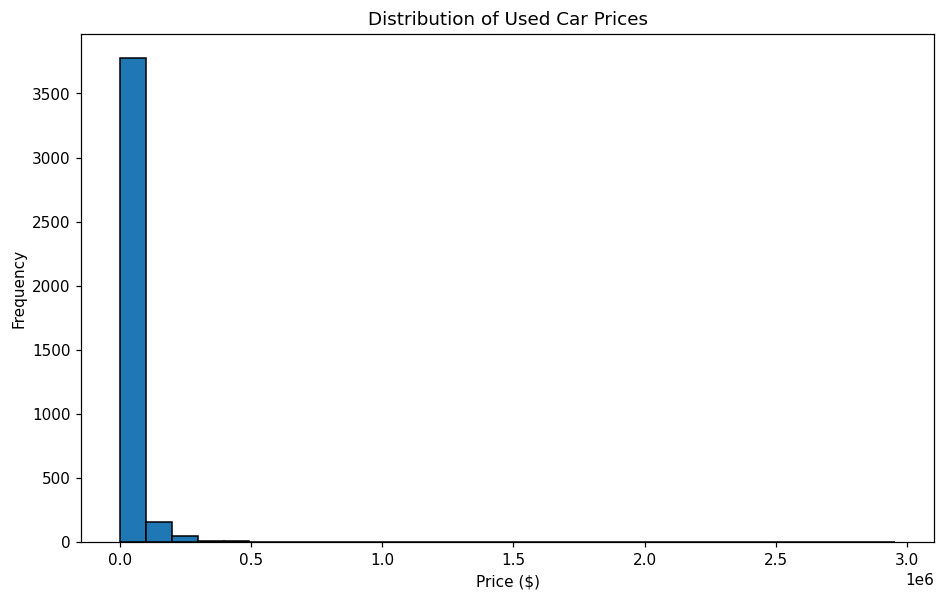

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(df['price'], bins=30, edgecolor='black')

plt.title('Distribution of Used Car Prices')
plt.xlabel('Price ($)')
plt.ylabel('Frequency')

plt.show()

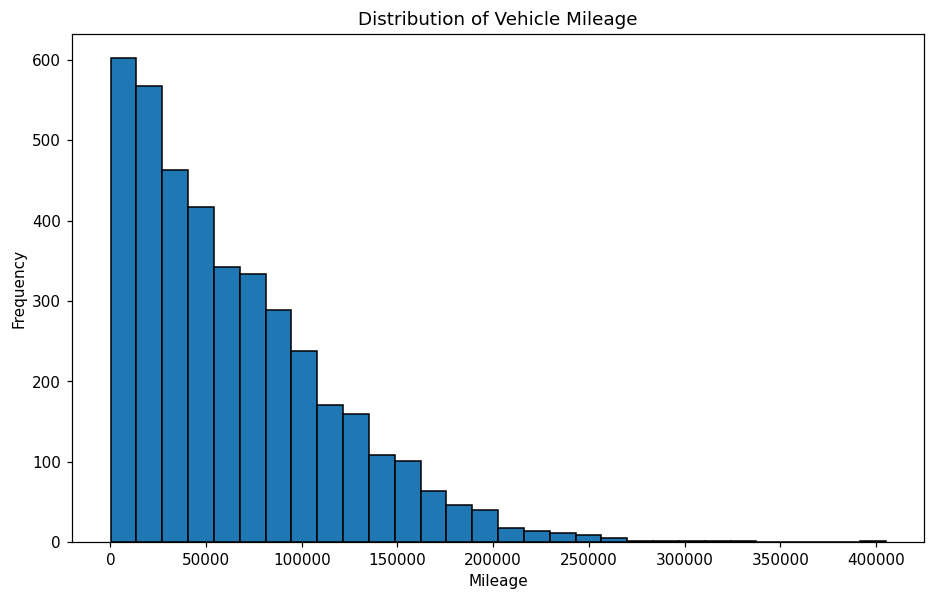

In [16]:
plt.figure(figsize=(10, 6))

plt.hist(df['milage'], bins=30, edgecolor='black')

plt.title('Distribution of Vehicle Mileage')
plt.xlabel('Mileage')
plt.ylabel('Frequency')

plt.show()

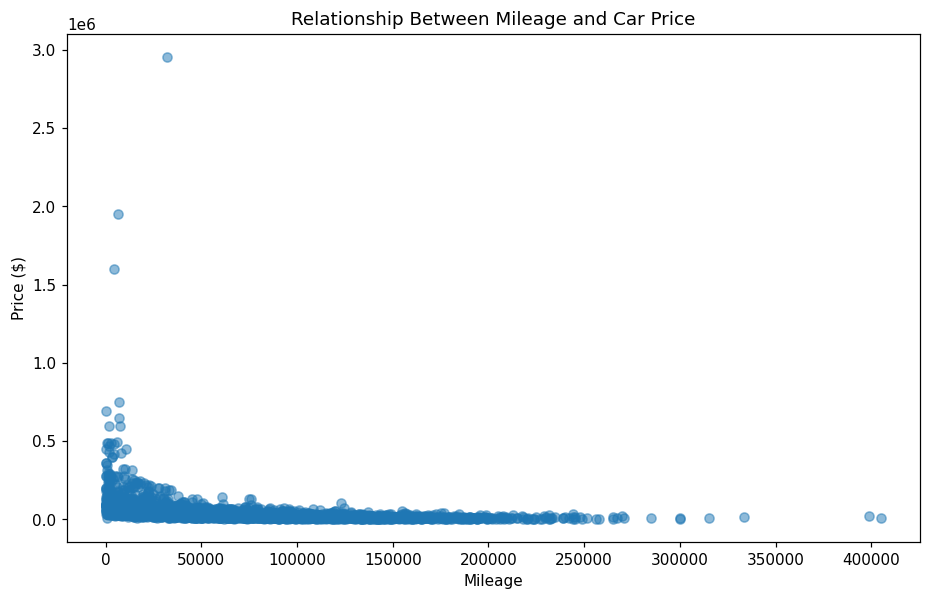

In [17]:
plt.figure(figsize=(10, 6))

plt.scatter(df['milage'], df['price'], alpha=0.5)

plt.title('Relationship Between Mileage and Car Price')
plt.xlabel('Mileage')
plt.ylabel('Price ($)')

plt.show()

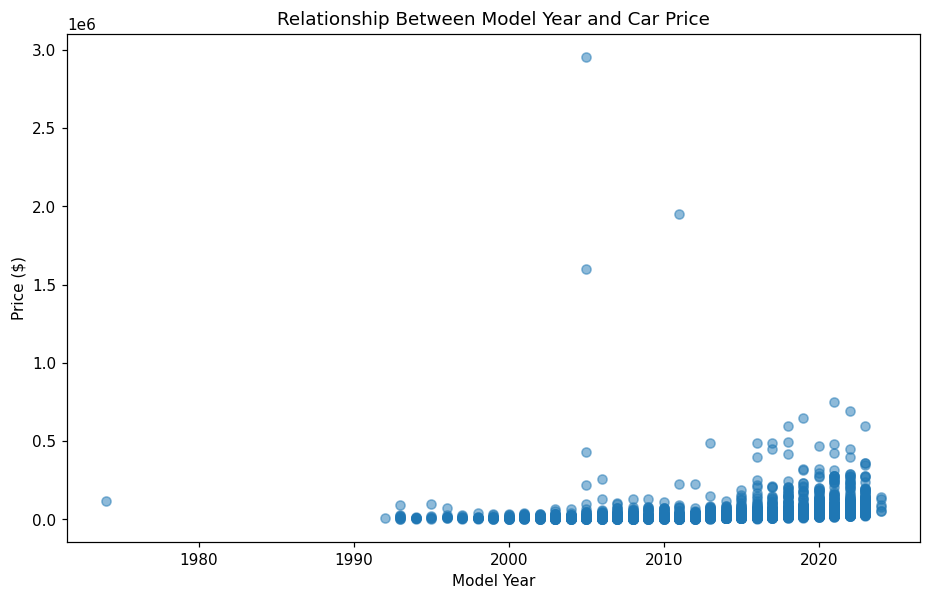

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(df['model_year'], df['price'], alpha=0.5)

plt.title('Relationship Between Model Year and Car Price')
plt.xlabel('Model Year')
plt.ylabel('Price ($)')

plt.show()

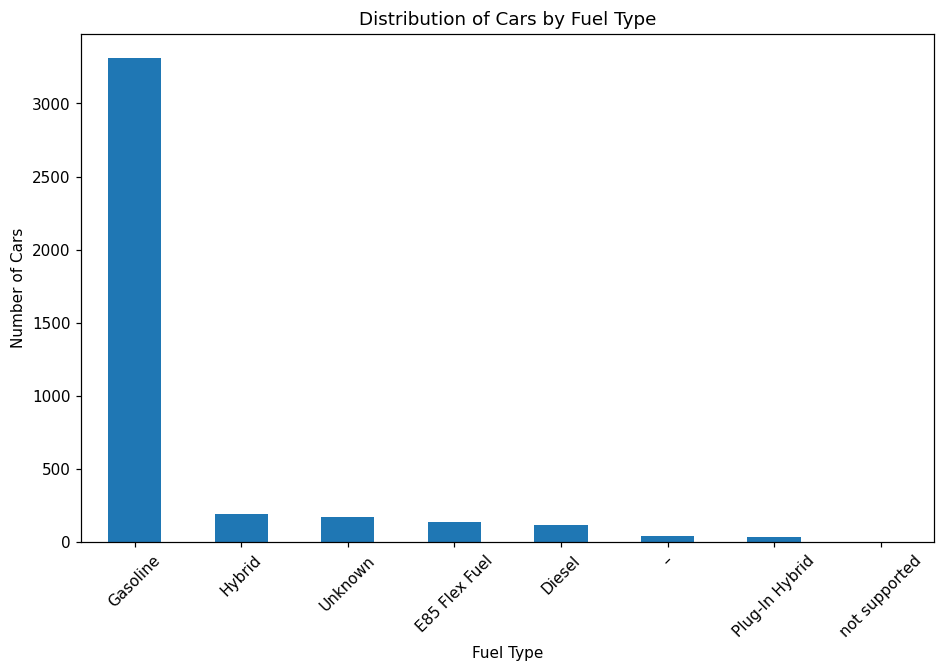

In [19]:
plt.figure(figsize=(10, 6))

df['fuel_type'].value_counts().plot(kind='bar')

plt.title('Distribution of Cars by Fuel Type')
plt.xlabel('Fuel Type')
plt.ylabel('Number of Cars')
plt.xticks(rotation=45)

plt.show()

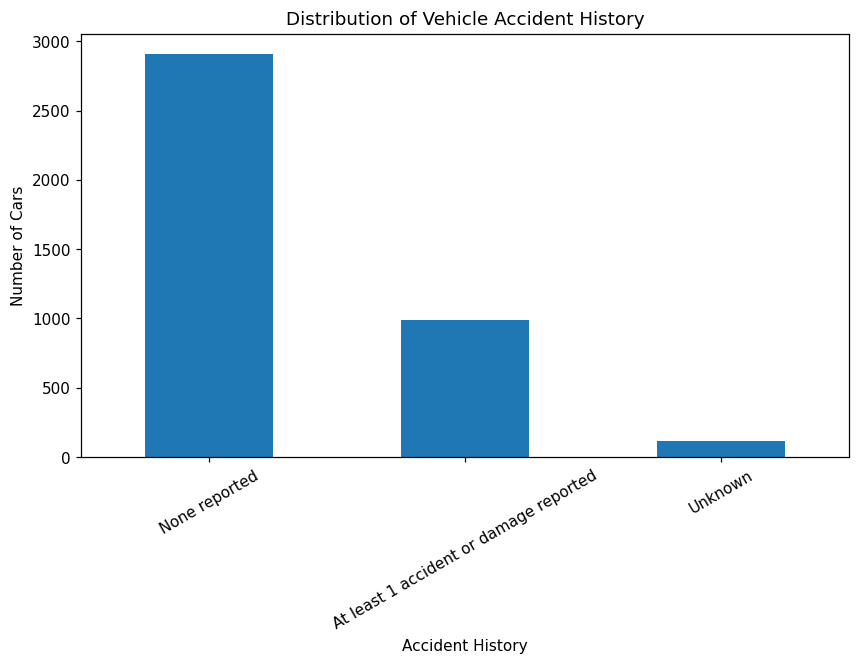

In [20]:
plt.figure(figsize=(9, 5))

df['accident'].value_counts().plot(kind='bar')

plt.title('Distribution of Vehicle Accident History')
plt.xlabel('Accident History')
plt.ylabel('Number of Cars')
plt.xticks(rotation=30)

plt.show()

In [21]:
numerical_data = df[['model_year', 'milage', 'price']]

correlation_matrix = numerical_data.corr()

correlation_matrix

,model_year,milage,price
model_year,1.000000,-0.617720,0.199496
milage,-0.617720,1.000000,-0.305528
price,0.199496,-0.305528,1.000000


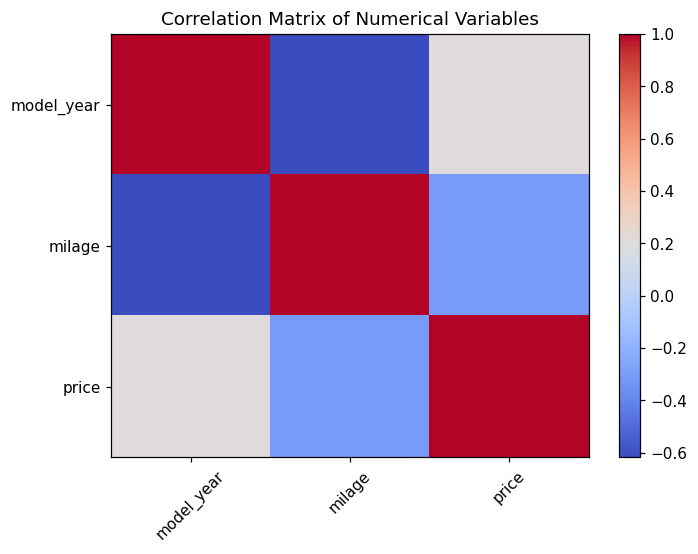

In [22]:
plt.figure(figsize=(7, 5))

plt.imshow(correlation_matrix, cmap='coolwarm', aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns,
    rotation=45
)

plt.yticks(
    range(len(correlation_matrix.columns)),
    correlation_matrix.columns
)

plt.title('Correlation Matrix of Numerical Variables')

plt.show()

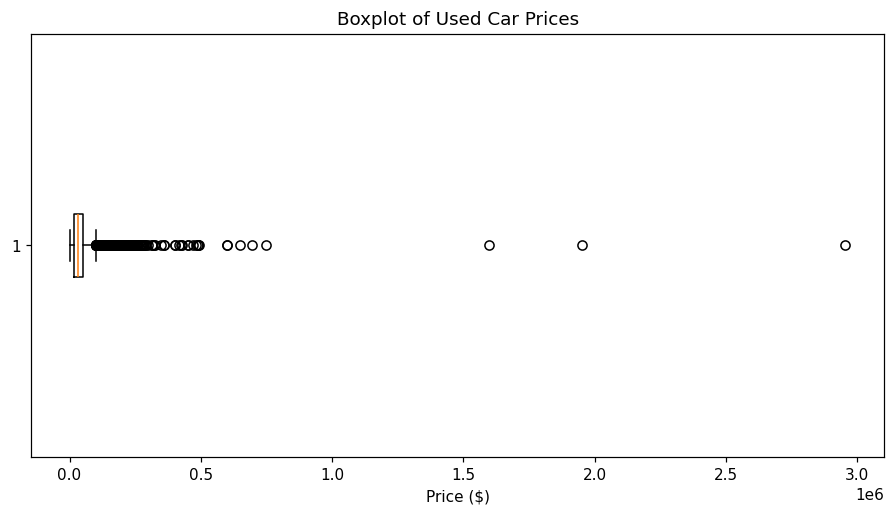

In [23]:
plt.figure(figsize=(10, 5))

plt.boxplot(df['price'], orientation='horizontal')

plt.title('Boxplot of Used Car Prices')
plt.xlabel('Price ($)')

plt.show()

In [24]:
df.nlargest(15, 'price')[
    ['brand', 'model', 'model_year', 'milage', 'price']
]

,brand,model,model_year,milage,price
693,Maserati,Quattroporte Base,2005,32000.0,2954083.0
229,Bugatti,Veyron 16.4 Grand Sport,2011,6330.0,1950995.0
3046,Porsche,Carrera GT Base,2005,4400.0,1599000.0
1356,Lamborghini,Aventador SVJ Base,2021,6987.0,749950.0
624,Rolls-Royce,Cullinan,2022,398.0,695000.0
979,Lamborghini,Aventador SVJ Base,2019,6929.0,649999.0
1615,Rolls-Royce,Phantom,2023,1560.0,599995.0
1508,Rolls-Royce,Phantom,2018,7585.0,599000.0
3655,Lamborghini,Aventador S Base,2018,5858.0,491836.0
1061,Dodge,Viper GTC,2017,1389.0,489995.0


In [25]:
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

price_outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

print("Number of price outliers:", len(price_outliers))

Q1: 17200.0
Q3: 49990.0
IQR: 32790.0
Lower bound: -31985.0
Upper bound: 99175.0
Number of price outliers: 244


In [26]:
df[['brand', 'model', 'fuel_type', 'engine',
    'transmission', 'ext_col', 'int_col',
    'accident', 'clean_title']].nunique()

brand             57
model           1898
fuel_type          8
engine          1146
transmission      62
ext_col          319
int_col          156
accident           3
clean_title        2
dtype: int64

## Transform the target and split the data

Log transformation reduces skew. Use one reproducible 80/20 split; fit preprocessing only on training data.

In [27]:
import numpy as np

df['log_price'] = np.log1p(df['price'])

In [28]:
print("Original price skewness:", df['price'].skew())
print("Log price skewness:", df['log_price'].skew())

Original price skewness: 19.51355120421606
Log price skewness: 0.10572635355073637


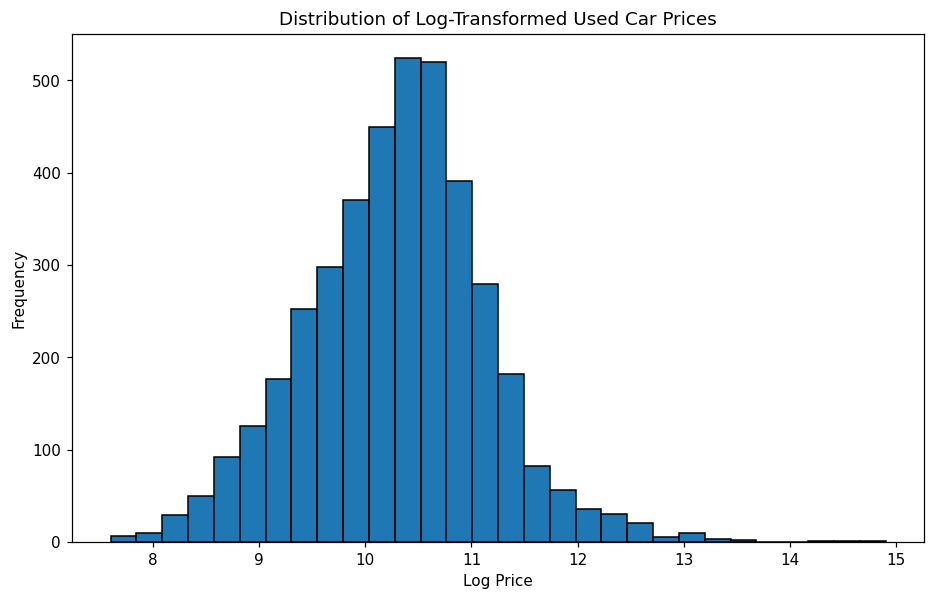

In [29]:
plt.figure(figsize=(10, 6))

plt.hist(df['log_price'], bins=30, edgecolor='black')

plt.title('Distribution of Log-Transformed Used Car Prices')
plt.xlabel('Log Price')
plt.ylabel('Frequency')

plt.show()

In [30]:
features = [
    'model_year',
    'milage',
    'brand',
    'fuel_type',
    'transmission',
    'accident',
    'clean_title'
]

X = df[features]
y = df['log_price']

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3207, 7)
X_test: (802, 7)
y_train: (3207,)
y_test: (802,)


In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = [
    'model_year',
    'milage'
]

categorical_features = [
    'brand',
    'fuel_type',
    'transmission',
    'accident',
    'clean_title'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

## Train and evaluate three regressors

Use Linear Regression, Random Forest and Gradient Boosting with the original coursework hyperparameters. Compare metrics on dollars as well as log prices.

In [33]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['model_year', 'milage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['brand', 'fuel_type',
                                                   'transmission', 'accident',
                                                   'clean_title'])])),
                ('regressor', LinearRegression())])

In [34]:
y_pred_linear_log = linear_model.predict(X_test)

In [35]:
y_pred_linear = np.expm1(y_pred_linear_log)
y_test_actual = np.expm1(y_test)

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_mae = mean_absolute_error(y_test_actual, y_pred_linear)
linear_mse = mean_squared_error(y_test_actual, y_pred_linear)
linear_rmse = np.sqrt(linear_mse)
linear_r2 = r2_score(y_test_actual, y_pred_linear)

print("Linear Regression Results")
print("MAE:", linear_mae)
print("RMSE:", linear_rmse)
print("R²:", linear_r2)

Linear Regression Results
MAE: 20728.129341954158
RMSE: 138178.8037752048
R²: 0.06586191223474247


In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['model_year', 'milage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['brand', 'fuel_type',
                                                   'transmission', 'accident',
                                                   'clean_title'])])),
                ('regressor',
                 RandomForestRegressor(n_estimators=200, random_state=42))])

In [38]:
y_pred_rf_log = rf_model.predict(X_test)

y_pred_rf = np.expm1(y_pred_rf_log)

In [39]:
rf_mae = mean_absolute_error(y_test_actual, y_pred_rf)
rf_mse = mean_squared_error(y_test_actual, y_pred_rf)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test_actual, y_pred_rf)

print("Random Forest Results")
print("MAE:", rf_mae)
print("RMSE:", rf_rmse)
print("R²:", rf_r2)

Random Forest Results
MAE: 20440.13866910684
RMSE: 135359.03271859195
R²: 0.10359822638994876


In [40]:
preprocessor_dense = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_features)
    ]
)

In [41]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline(steps=[
    ('preprocessor', preprocessor_dense),
    ('regressor', GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        random_state=42
    ))
])

gb_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['model_year', 'milage']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['brand', 'fuel_type',
                                                   'transmission', 'accident',
                                                   'clean_title'])])),
                ('regressor',
                 GradientBoostingRegressor(learning_rate=0.05, n_estimators=200,
                                           random_state=42))])

In [42]:
y_pred_gb_log = gb_model.predict(X_test)

y_pred_gb = np.expm1(y_pred_gb_log)

In [43]:
gb_mae = mean_absolute_error(y_test_actual, y_pred_gb)
gb_mse = mean_squared_error(y_test_actual, y_pred_gb)
gb_rmse = np.sqrt(gb_mse)
gb_r2 = r2_score(y_test_actual, y_pred_gb)

print("Gradient Boosting Results")
print("MAE:", gb_mae)
print("RMSE:", gb_rmse)
print("R²:", gb_r2)

Gradient Boosting Results
MAE: 21344.427103341783
RMSE: 137117.23928205878
R²: 0.08015988863252199


In [44]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE': [
        linear_mae,
        rf_mae,
        gb_mae
    ],
    'RMSE': [
        linear_rmse,
        rf_rmse,
        gb_rmse
    ],
    'R2': [
        linear_r2,
        rf_r2,
        gb_r2
    ]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,20728.129342,138178.803775,0.065862
1,Random Forest,20440.138669,135359.032719,0.103598
2,Gradient Boosting,21344.427103,137117.239282,0.080160


In [45]:
linear_mae_log = mean_absolute_error(y_test, y_pred_linear_log)
linear_rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_linear_log))
linear_r2_log = r2_score(y_test, y_pred_linear_log)

rf_mae_log = mean_absolute_error(y_test, y_pred_rf_log)
rf_rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_rf_log))
rf_r2_log = r2_score(y_test, y_pred_rf_log)

gb_mae_log = mean_absolute_error(y_test, y_pred_gb_log)
gb_rmse_log = np.sqrt(mean_squared_error(y_test, y_pred_gb_log))
gb_r2_log = r2_score(y_test, y_pred_gb_log)

log_results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest',
        'Gradient Boosting'
    ],
    'MAE_Log': [
        linear_mae_log,
        rf_mae_log,
        gb_mae_log
    ],
    'RMSE_Log': [
        linear_rmse_log,
        rf_rmse_log,
        gb_rmse_log
    ],
    'R2_Log': [
        linear_r2_log,
        rf_r2_log,
        gb_r2_log
    ]
})

log_results

,Model,MAE_Log,RMSE_Log,R2_Log
0,Linear Regression,0.332970,0.496543,0.683369
1,Random Forest,0.327597,0.470525,0.715682
2,Gradient Boosting,0.336742,0.479103,0.705220


## Visualise model performance

A useful log-price fit can coexist with poor dollar-price performance because very expensive listings have large errors.

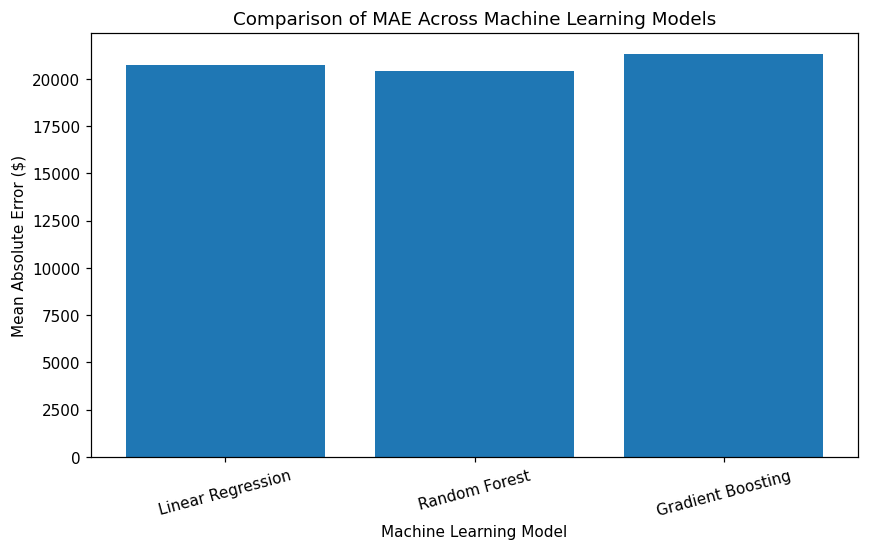

In [46]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['MAE'])

plt.title('Comparison of MAE Across Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Mean Absolute Error ($)')
plt.xticks(rotation=15)

plt.show()

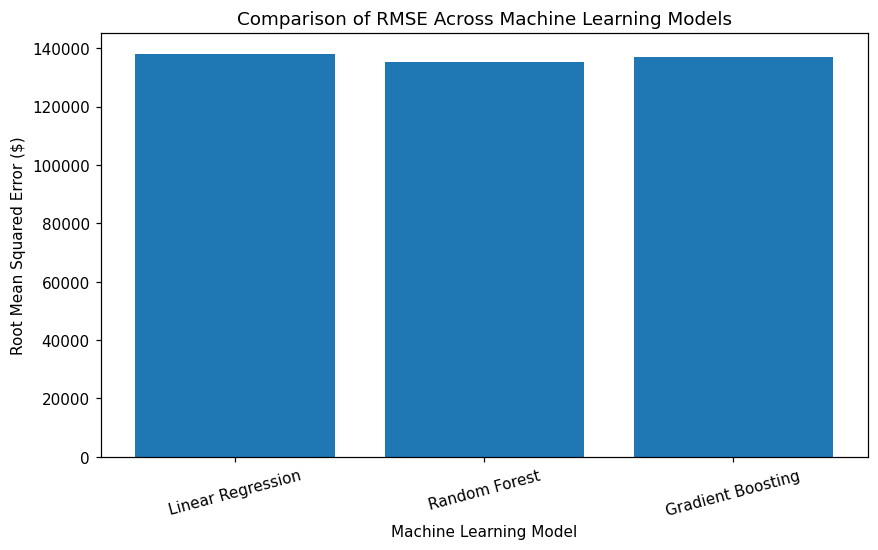

In [47]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['RMSE'])

plt.title('Comparison of RMSE Across Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('Root Mean Squared Error ($)')
plt.xticks(rotation=15)

plt.show()

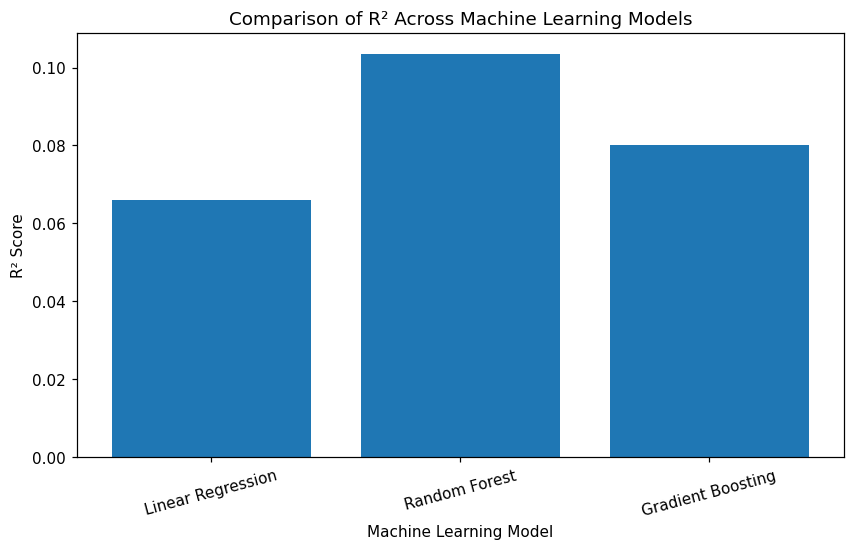

In [48]:
plt.figure(figsize=(9, 5))

plt.bar(results['Model'], results['R2'])

plt.title('Comparison of R² Across Machine Learning Models')
plt.xlabel('Machine Learning Model')
plt.ylabel('R² Score')
plt.xticks(rotation=15)

plt.show()

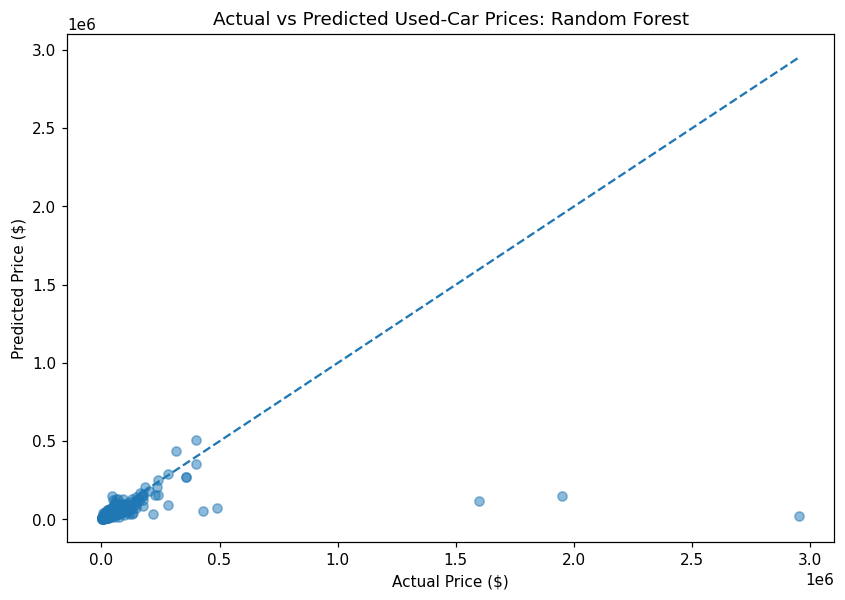

In [49]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test_actual, y_pred_rf, alpha=0.5)

minimum = min(y_test_actual.min(), y_pred_rf.min())
maximum = max(y_test_actual.max(), y_pred_rf.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.xlabel('Actual Price ($)')
plt.ylabel('Predicted Price ($)')
plt.title('Actual vs Predicted Used-Car Prices: Random Forest')

plt.show()

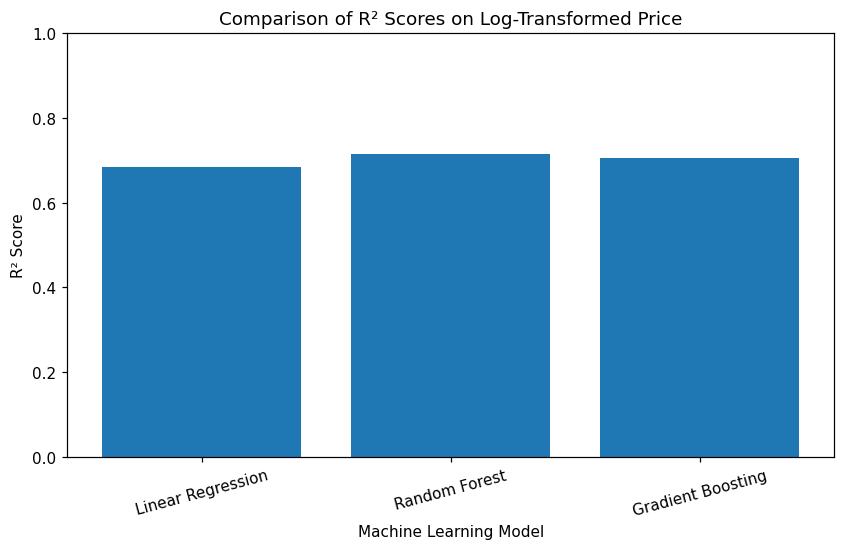

In [50]:
plt.figure(figsize=(9, 5))

plt.bar(log_results['Model'], log_results['R2_Log'])

plt.title('Comparison of R² Scores on Log-Transformed Price')
plt.xlabel('Machine Learning Model')
plt.ylabel('R² Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

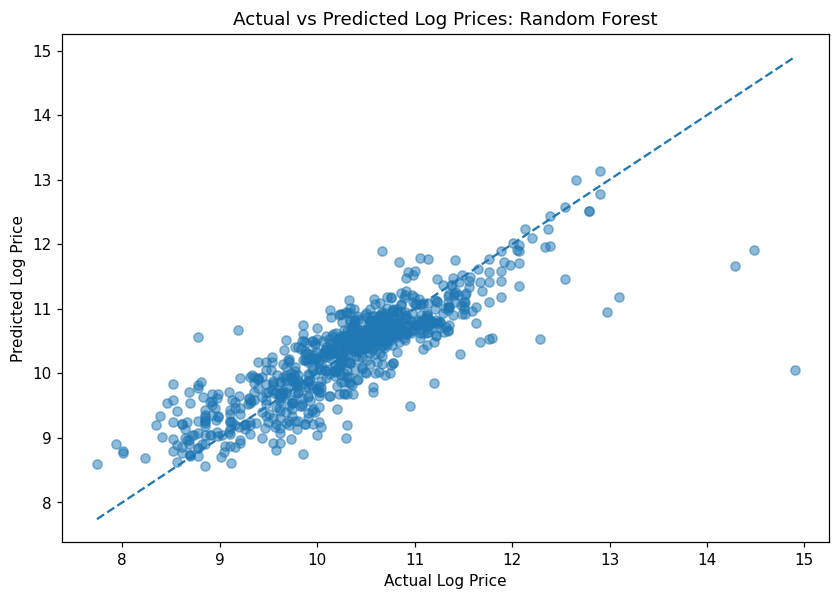

In [51]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred_rf_log, alpha=0.5)

minimum = min(y_test.min(), y_pred_rf_log.min())
maximum = max(y_test.max(), y_pred_rf_log.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    linestyle='--'
)

plt.title('Actual vs Predicted Log Prices: Random Forest')
plt.xlabel('Actual Log Price')
plt.ylabel('Predicted Log Price')

plt.show()

## Inspect feature importance

Impurity-based Random Forest importance describes this fitted model; it is not causal and can favour high-cardinality or continuous features.

In [52]:
fitted_preprocessor = rf_model.named_steps['preprocessor']

In [53]:
feature_names = fitted_preprocessor.get_feature_names_out()

feature_names

array(['num__model_year', 'num__milage', 'cat__brand_Acura',
       'cat__brand_Alfa', 'cat__brand_Aston', 'cat__brand_Audi',
       'cat__brand_BMW', 'cat__brand_Bentley', 'cat__brand_Buick',
       'cat__brand_Cadillac', 'cat__brand_Chevrolet',
       'cat__brand_Chrysler', 'cat__brand_Dodge', 'cat__brand_FIAT',
       'cat__brand_Ferrari', 'cat__brand_Ford', 'cat__brand_GMC',
       'cat__brand_Genesis', 'cat__brand_Honda', 'cat__brand_Hummer',
       'cat__brand_Hyundai', 'cat__brand_INFINITI', 'cat__brand_Jaguar',
       'cat__brand_Jeep', 'cat__brand_Karma', 'cat__brand_Kia',
       'cat__brand_Lamborghini', 'cat__brand_Land', 'cat__brand_Lexus',
       'cat__brand_Lincoln', 'cat__brand_Lotus', 'cat__brand_Lucid',
       'cat__brand_MINI', 'cat__brand_Maserati', 'cat__brand_Maybach',
       'cat__brand_Mazda', 'cat__brand_McLaren',
       'cat__brand_Mercedes-Benz', 'cat__brand_Mercury',
       'cat__brand_Mitsubishi', 'cat__brand_Nissan',
       'cat__brand_Plymouth', 'cat__bran

In [54]:
importances = rf_model.named_steps['regressor'].feature_importances_

importances

array([1.50798856e-01, 5.76728056e-01, 1.31472328e-03, 4.47725257e-04,
       1.43759375e-03, 3.10101246e-03, 5.57941526e-03, 1.16329997e-02,
       4.53938487e-04, 4.40554647e-03, 5.05540028e-03, 2.52164782e-03,
       1.74926828e-03, 4.21549762e-04, 8.79349811e-03, 3.28400389e-03,
       2.15606700e-03, 3.71014788e-04, 1.47565517e-03, 1.82032070e-03,
       6.45751246e-03, 6.98153399e-04, 7.18785652e-04, 1.86914190e-03,
       2.56403852e-05, 3.07496100e-03, 2.13303041e-02, 5.33541913e-03,
       3.54560695e-03, 1.33963142e-03, 6.44247161e-05, 8.40990666e-05,
       3.14694488e-03, 9.31326836e-04, 3.73735465e-04, 3.12131167e-03,
       2.95677654e-03, 9.82980339e-03, 1.24311755e-05, 2.55193480e-03,
       4.12926767e-03, 2.34036020e-05, 6.52387031e-06, 6.64178978e-04,
       2.76692398e-02, 1.20526993e-03, 5.08308562e-04, 1.01451633e-02,
       7.96466068e-06, 3.08236203e-04, 1.99774283e-04, 8.80400549e-04,
       1.65537007e-04, 9.06004770e-04, 4.81768117e-03, 2.66610323e-03,
      

In [55]:
feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
1,num__milage,0.576728
0,num__model_year,0.150799
44,cat__brand_Porsche,0.027669
26,cat__brand_Lamborghini,0.021330
7,cat__brand_Bentley,0.011633
47,cat__brand_Rolls-Royce,0.010145
58,cat__fuel_type_Diesel,0.009906
37,cat__brand_Mercedes-Benz,0.009830
104,cat__transmission_A/T,0.008842
14,cat__brand_Ferrari,0.008793


In [56]:
feature_importance['Feature'] = (
    feature_importance['Feature']
    .str.replace('num__', '', regex=False)
    .str.replace('cat__', '', regex=False)
)

feature_importance.head(15)

,Feature,Importance
1,milage,0.576728
0,model_year,0.150799
44,brand_Porsche,0.027669
26,brand_Lamborghini,0.021330
7,brand_Bentley,0.011633
47,brand_Rolls-Royce,0.010145
58,fuel_type_Diesel,0.009906
37,brand_Mercedes-Benz,0.009830
104,transmission_A/T,0.008842
14,brand_Ferrari,0.008793


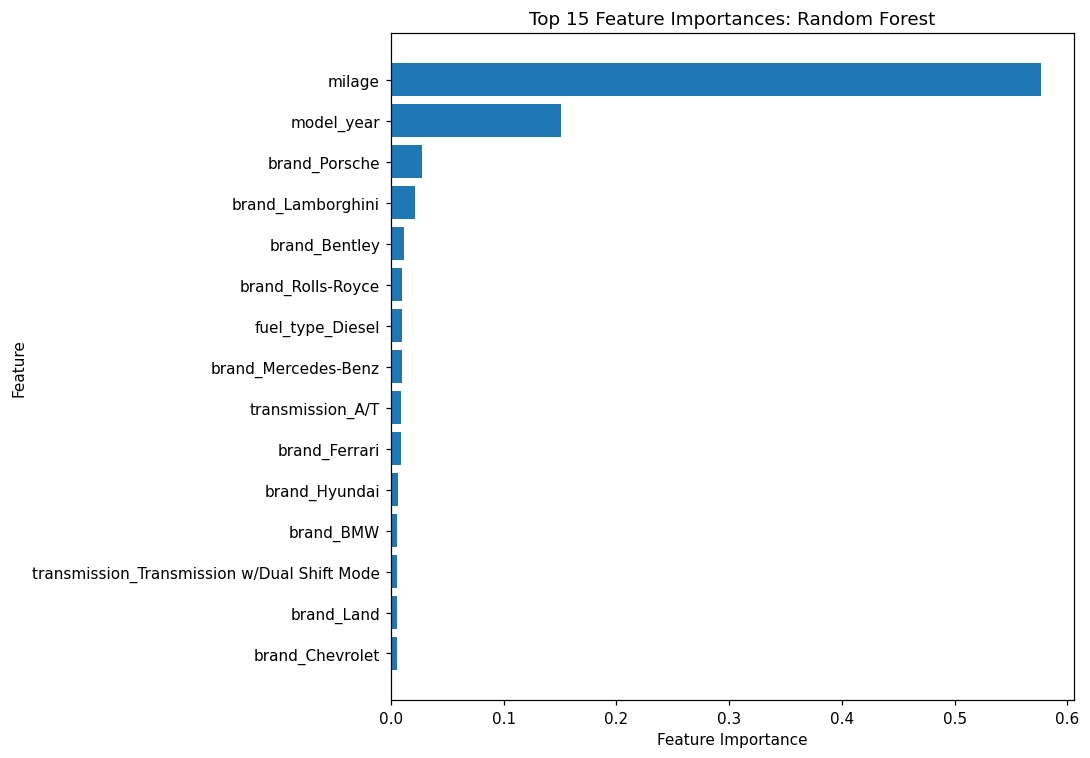

In [57]:
top_features = feature_importance.head(15).sort_values(
    by='Importance',
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.title('Top 15 Feature Importances: Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [58]:
feature_importance['Original_Feature'] = feature_importance['Feature']

for col in categorical_features:
    feature_importance.loc[
        feature_importance['Feature'].str.startswith(col + '_'),
        'Original_Feature'
    ] = col

grouped_importance = (
    feature_importance
    .groupby('Original_Feature')['Importance']
    .sum()
    .sort_values(ascending=False)
)

grouped_importance

Original_Feature
milage          0.576728
brand           0.179196
model_year      0.150799
transmission    0.059425
fuel_type       0.020314
accident        0.010210
clean_title     0.003329
Name: Importance, dtype: float64

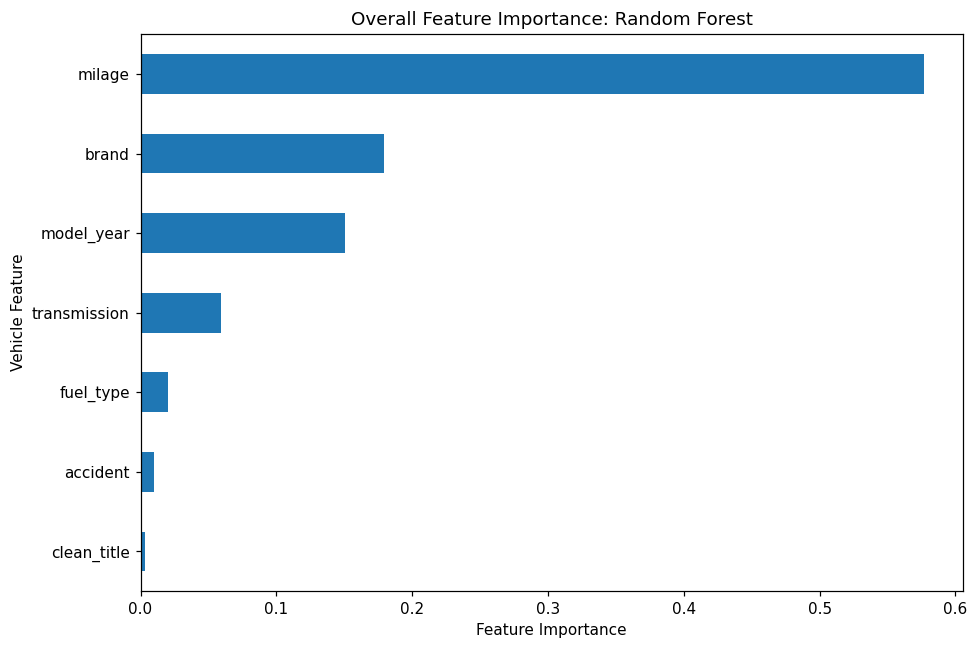

In [59]:
plt.figure(figsize=(9, 6))

grouped_importance.sort_values().plot(kind='barh')

plt.title('Overall Feature Importance: Random Forest')
plt.xlabel('Feature Importance')
plt.ylabel('Vehicle Feature')

plt.tight_layout()
plt.show()

## Compare with a simple baseline

A training-median prediction provides context for whether the models improve on a simple rule. This comparison was added for the portfolio review.

In [60]:
from sklearn.dummy import DummyRegressor
baseline_log = DummyRegressor(strategy="median").fit(X_train, y_train)
baseline_pred_log = baseline_log.predict(X_test)
baseline_pred_dollars = np.expm1(baseline_pred_log)
print("Training-median baseline, dollars")
print("MAE:", mean_absolute_error(y_test_actual, baseline_pred_dollars))
print("RMSE:", np.sqrt(mean_squared_error(y_test_actual, baseline_pred_dollars)))
print("R2:", r2_score(y_test_actual, baseline_pred_dollars))
print("Training-median baseline, log-price R2:", r2_score(y_test, baseline_pred_log))

Training-median baseline, dollars
MAE: 32865.97007481297
RMSE: 144218.91711273388
R2: -0.01758965514338584
Training-median baseline, log-price R2: -0.0036365498309458566


## Interpretation and limitations

Prices are advertised asking prices, not verified sale prices. Large positive outliers are retained and strongly affect dollar errors. Log-price R-squared must not be presented as percentage price accuracy. This is a single random holdout, not cross-validation or a temporal test. Missing engine detail, listing age and location limit interpretation. Feature importance does not measure causal effects. Validate the dataset provenance before distributing the raw CSV.